In [ ]:
%pip install -q tiktoken

In [ ]:
import tiktoken

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
from transformers import AutoTokenizer
import math

n_embd = 768
n_head = 12
n_layer = 12
block_size = 1024
vocab_size = 50257
dropout = 0.1
from torch.nn import functional as F
from urllib.request import urlopen

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(1337)

n_embd = 768
n_head = 12
n_layer = 12
block_size = 1024
vocab_size = 50257
dropout = 0.0
from transformers import GPT2LMHeadModel
url = (
    "https://raw.githubusercontent.com/karpathy/"
    "char-rnn/master/data/tinyshakespeare/input.txt"
)

text = urlopen(url).read().decode("utf-8")

enc = tiktoken.get_encoding("gpt2")
tokens = torch.tensor(enc.encode(text), dtype=torch.long)

class MultiHeadAttention(nn.Module):
    def __init__(self):
        super().__init__()

        self.c_attn = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)

        self.attn_dropout = nn.Dropout(dropout)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size)),
            persistent=False,
        )

    def forward(self, x):
        B, T, C = x.shape
        head_size = C // n_head

        q, k, v = self.c_attn(x).split(C, dim=-1)

        q = q.view(B, T, n_head, head_size).transpose(1, 2)
        k = k.view(B, T, n_head, head_size).transpose(1, 2)
        v = v.view(B, T, n_head, head_size).transpose(1, 2)

        wei = q @ k.transpose(-2, -1) * head_size**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)
        wei = self.attn_dropout(wei)

        out = wei @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)

        out = self.proj(out)
        return self.dropout(out)
class FeedFoward(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(approximate="tanh"),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self):
        super().__init__()

        self.sa = MultiHeadAttention()
        self.ffwd = FeedFoward()
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class GPTLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)

        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)

        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding_table.weight

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= block_size

        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(
            torch.arange(T, device=idx.device)
        )

        x = self.dropout(tok_emb + pos_emb)
        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(B * T, vocab_size),
                targets.reshape(B * T),
            )

        return logits, loss

# ***GÖREV 1***

In [ ]:
class DataLoaderLite:
    def __init__(self, tokens, B, T):
        self.tokens = tokens
        self.B = B
        self.T = T
        self.current_position = 0

        assert len(tokens) > 1
        assert T <= block_size

        self.num_batches = math.ceil((len(tokens) - 1) / (B * T))

    def next_batch(self):
        B, T = self.B, self.T
        start = self.current_position

        buffer = self.tokens[start : start + B * T + 1]
        valid_tokens = len(buffer) - 1

        # Son batch eksikse boyutunu tamamla.
        if len(buffer) < B * T + 1:
            padding = torch.full(
                (B * T + 1 - len(buffer),),
                enc.eot_token,
                dtype=torch.long,
            )
            buffer = torch.cat((buffer, padding))

        x = buffer[:-1].reshape(B, T)
        y = buffer[1:].clone()
        y[valid_tokens:] = -100
        y = y.reshape(B, T)

        self.current_position += B * T

        if self.current_position >= len(self.tokens) - 1:
            self.current_position = 0

        return x, y

In [ ]:
torch.manual_seed(1337)

model_train = GPTLanguageModel()

# Önceki sınıfımızda zaten vardı; burada açıkça gösteriyoruz.
model_train.lm_head.weight = model_train.token_embedding_table.weight

for name, parameter in model_train.named_parameters():
    if parameter.dim() == 2:
        std = 0.02

        if name.endswith(("sa.proj.weight", "ffwd.net.2.weight")):
            std *= (2 * n_layer) ** -0.5

        nn.init.normal_(parameter, mean=0.0, std=std)

    elif name.endswith("bias"):
        nn.init.zeros_(parameter)

    else:
        nn.init.ones_(parameter)

model_train = model_train.to(device)

print(
    "Embedding ve LM head aynı parametre mi?",
    model_train.lm_head.weight
    is model_train.token_embedding_table.weight,
)

print(
    "Token embedding std:",
    model_train.token_embedding_table.weight.std().item(),
)

print(
    "Attention çıkış ağırlığı std:",
    model_train.blocks[0].sa.proj.weight.std().item(),
)

print(
    "MLP çıkış ağırlığı std:",
    model_train.blocks[0].ffwd.net[2].weight.std().item(),
)

print("Residual için hedef std:", 0.02 / math.sqrt(2 * n_layer))

Embedding ve LM head aynı parametre mi? True
Token embedding std: 0.019998757168650627
Attention çıkış ağırlığı std: 0.004079954698681831
MLP çıkış ağırlığı std: 0.0040829977951943874
Residual için hedef std: 0.004082482904638631


In [ ]:
train_loader = DataLoaderLite(tokens, B=4, T=32)

x, y = train_loader.next_batch()

print("Bir epoch içindeki batch sayısı:", train_loader.num_batches)
print("x boyutu:", x.shape)
print("y boyutu:", y.shape)

print("\nİlk 10 giriş tokenı:", x[0, :10].tolist())
print("İlk 10 hedef token:", y[0, :10].tolist())

print("\nİlk satırın metni:")
print(enc.decode(x[0].tolist()))

print("\nLoader'ın yeni konumu:", train_loader.current_position)

# Kontrol sırasında aldığımız batch'i eğitimde atlamayalım.
train_loader.current_position = 0

Bir epoch içindeki batch sayısı: 2641
x boyutu: torch.Size([4, 32])
y boyutu: torch.Size([4, 32])

İlk 10 giriş tokenı: [5962, 22307, 25, 198, 8421, 356, 5120, 597, 2252, 11]
İlk 10 hedef token: [22307, 25, 198, 8421, 356, 5120, 597, 2252, 11, 3285]

İlk satırın metni:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are

Loader'ın yeni konumu: 128


In [ ]:
tied_params = sum(p.numel() for p in model_train.parameters())

saved_params = model_train.token_embedding_table.weight.numel()
untied_params = tied_params + saved_params

print(f"Weight tying olmadan: {untied_params:,}")
print(f"Weight tying ile:     {tied_params:,}")
print(f"Kazanılan parametre:  {saved_params:,}")
print(f"Parametre azalması:   %{100 * saved_params / untied_params:.2f}")

Weight tying olmadan: 163,037,184
Weight tying ile:     124,439,808
Kazanılan parametre:  38,597,376
Parametre azalması:   %23.67


In [ ]:
x, y = train_loader.next_batch()

In [ ]:
optimizer = torch.optim.AdamW(
    model_train.parameters(),
    lr=3e-4,
    weight_decay=0.01,
)

train_loader.current_position = 0
model_train.train()

losses = []
total_loss = 0.0
total_tokens = 0

for step in range(train_loader.num_batches):
    x, y = train_loader.next_batch()
    x = x.to(device)
    y = y.to(device)

    optimizer.zero_grad(set_to_none=True)

    _, loss = model_train(x, y)
    loss.backward()
    optimizer.step()

    loss_value = loss.item()
    valid_tokens = (y != -100).sum().item()

    losses.append(loss_value)
    total_loss += loss_value * valid_tokens
    total_tokens += valid_tokens

    if step % 100 == 0 or step == train_loader.num_batches - 1:
        print(
            f"Adım {step + 1}/{train_loader.num_batches} "
            f"| loss: {loss_value:.4f}"
        )

print("\nBir epoch tamamlandı.")
print("Eğitimde kullanılan hedef token sayısı:", total_tokens)
print("Beklenen hedef token sayısı:", len(tokens) - 1)
print(f"Eğitim boyunca ortalama loss: {total_loss / total_tokens:.4f}")

assert total_tokens == len(tokens) - 1

Adım 1/2641 | loss: 11.0709
Adım 101/2641 | loss: 6.3850
Adım 201/2641 | loss: 5.3322
Adım 301/2641 | loss: 6.0680
Adım 401/2641 | loss: 4.5281
Adım 501/2641 | loss: 6.1360
Adım 601/2641 | loss: 5.9433
Adım 701/2641 | loss: 4.9871
Adım 801/2641 | loss: 4.5937
Adım 901/2641 | loss: 6.1548
Adım 1001/2641 | loss: 5.0918
Adım 1101/2641 | loss: 4.8111
Adım 1201/2641 | loss: 6.2359
Adım 1301/2641 | loss: 4.6923
Adım 1401/2641 | loss: 5.2179
Adım 1501/2641 | loss: 5.1447
Adım 1601/2641 | loss: 5.3083
Adım 1701/2641 | loss: 5.7614
Adım 1801/2641 | loss: 7.0243
Adım 1901/2641 | loss: 4.2978
Adım 2001/2641 | loss: 6.0949
Adım 2101/2641 | loss: 5.6547
Adım 2201/2641 | loss: 4.8787
Adım 2301/2641 | loss: 5.7404
Adım 2401/2641 | loss: 4.8982
Adım 2501/2641 | loss: 4.4686
Adım 2601/2641 | loss: 5.0272
Adım 2641/2641 | loss: 4.7341

Bir epoch tamamlandı.
Eğitimde kullanılan hedef token sayısı: 338024
Beklenen hedef token sayısı: 338024
Eğitim boyunca ortalama loss: 5.3628


In [ ]:
import matplotlib.pyplot as plt

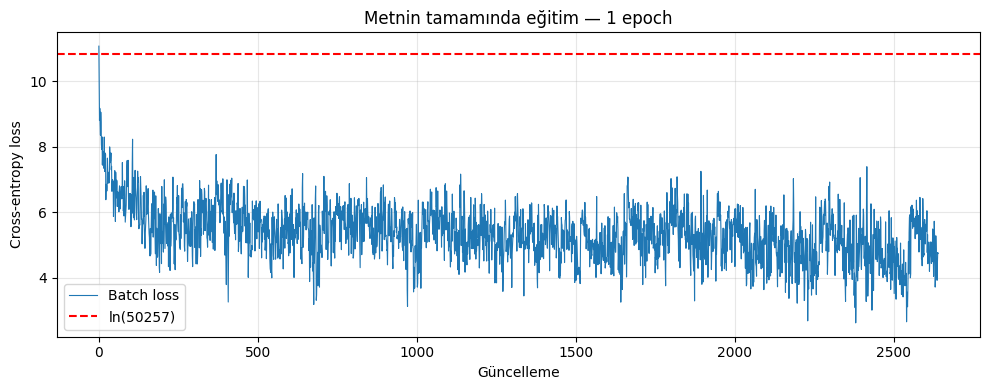

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(losses, linewidth=0.8, label="Batch loss")
plt.axhline(
    math.log(vocab_size),
    color="red",
    linestyle="--",
    label="ln(50257)",
)

plt.xlabel("Güncelleme")
plt.ylabel("Cross-entropy loss")
plt.title("Metnin tamamında eğitim — 1 epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ***GÖREV 2***

In [ ]:
import copy
import gc
import time
import statistics
import pandas as pd

from contextlib import nullcontext
from torch.nn.attention import sdpa_kernel, SDPBackend

assert torch.cuda.is_available(), "Colab'da GPU çalışma zamanını aç."

device = "cuda"

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("Compute capability:", torch.cuda.get_device_capability(0))

major, minor = torch.cuda.get_device_capability(0)

tf32_supported = major >= 8
bf16_supported = torch.cuda.is_bf16_supported(
    including_emulation=False
)

amp_dtype = torch.bfloat16 if bf16_supported else torch.float16

print("TF32 desteği:", tf32_supported)
print("Native BF16 desteği:", bf16_supported)
print("Kullanılacak AMP türü:", amp_dtype)

B = 2
T = 256
warmup_steps = 10
measure_steps = 30
repeats = 3

assert T <= block_size


model_train.zero_grad(set_to_none=True)
model_train = model_train.cpu()


if "optimizer" in globals():
    del optimizer

gc.collect()
torch.cuda.empty_cache()

PyTorch: 2.11.0+cu130
CUDA: 13.0
GPU: Tesla T4
Compute capability: (7, 5)
TF32 desteği: False
Native BF16 desteği: False
Kullanılacak AMP türü: torch.float16


In [ ]:
class SpeedAttention(MultiHeadAttention):
    def __init__(self, old_attention, use_flash=False):
        nn.Module.__init__(self)

        self.c_attn = old_attention.c_attn
        self.proj = old_attention.proj
        self.attn_dropout = old_attention.attn_dropout
        self.dropout = old_attention.dropout
        self.use_flash = use_flash

        self.register_buffer(
            "tril",
            old_attention.tril,
            persistent=False,
        )

    def forward(self, x):
        if not self.use_flash:
            return super().forward(x)

        B, T, C = x.shape
        head_size = C // n_head

        q, k, v = self.c_attn(x).split(C, dim=-1)

        q = q.view(B, T, n_head, head_size).transpose(1, 2)
        k = k.view(B, T, n_head, head_size).transpose(1, 2)
        v = v.view(B, T, n_head, head_size).transpose(1, 2)

        out = F.scaled_dot_product_attention(
            q, k, v,
            is_causal=True,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
        )

        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.dropout(self.proj(out))

In [ ]:
class SpeedModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x, y):
        logits, _ = self.model(x)

        return F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            y.reshape(-1),
        )

In [ ]:
def make_model(use_flash=False, padded_vocab=False):
    torch.manual_seed(1337)

    model = copy.deepcopy(model_train)

    for block in model.blocks:
        block.sa = SpeedAttention(block.sa, use_flash)

    if padded_vocab:
        old_weight = model.token_embedding_table.weight
        old_vocab, channels = old_weight.shape

        embedding = nn.Embedding(50304, channels)
        nn.init.normal_(embedding.weight, mean=0.0, std=0.02)

        with torch.no_grad():
            embedding.weight[:old_vocab].copy_(old_weight)

        model.token_embedding_table = embedding
        model.lm_head = nn.Linear(channels, 50304, bias=False)
        model.lm_head.weight = embedding.weight

    return SpeedModel(model).to(device).train()

In [ ]:
def benchmark(tf32=False, dtype=None,
              compiled=False, flash=False, padded_vocab=False):

    torch.set_float32_matmul_precision(
        "high" if tf32 else "highest"
    )

    loader = DataLoaderLite(tokens, B=B, T=T)
    model = make_model(flash, padded_vocab)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=3e-4,
        weight_decay=0.01,
        foreach=False,
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(dtype == torch.float16),
        init_scale=128.0,
    )

    # Gerçekten yapılan optimizer güncellemelerini say.
    updates = [0]

    def count_update(optimizer, args, kwargs):
        updates[0] += 1

    opt.register_step_post_hook(count_update)

    if compiled:
        model = torch.compile(model, fullgraph=True)

    def train_step():
        x, y = loader.next_batch()
        x, y = x.to(device), y.to(device)

        opt.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=dtype if dtype is not None else torch.float16,
            enabled=(dtype is not None),
        ):
            loss = model(x, y)

        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()

        return loss.detach()

    attention_context = (
        sdpa_kernel(SDPBackend.FLASH_ATTENTION)
        if flash else nullcontext()
    )

    with attention_context:
        torch.cuda.synchronize()
        warmup_start = time.perf_counter()

        for _ in range(warmup_steps):
            loss = train_step()

        torch.cuda.synchronize()
        warmup_seconds = time.perf_counter() - warmup_start

        times = []
        updates_before = updates[0]

        for _ in range(repeats):
            torch.cuda.synchronize()
            start = time.perf_counter()

            for _ in range(measure_steps):
                loss = train_step()

            torch.cuda.synchronize()
            elapsed = time.perf_counter() - start
            times.append(elapsed / measure_steps)

    expected_updates = repeats * measure_steps

    if updates[0] - updates_before != expected_updates:
        raise RuntimeError(
            "Ölçüm sırasında optimizer güncellemesi atlandı; "
            "bu hız sonucu kullanılmadı."
        )

    if not torch.isfinite(loss).item():
        raise RuntimeError("Loss sonlu değil; bu hız sonucu kullanılmadı.")

    seconds = statistics.median(times)

    return {
        "ms/adım": seconds * 1000,
        "token/s": B * T / seconds,
        "Isınma (sn)": warmup_seconds,
        "Son loss": loss.item(),
    }

In [ ]:
results = []

def skip_stage(name, reason):
    results.append({"Aşama": name, "Durum": reason})
    print(name, "->", reason)

def run_stage(name, **settings):
    print("\nÇalışıyor:", name)
    success = False

    try:
        result = benchmark(**settings)
        results.append({
            "Aşama": name,
            "Durum": "Ölçüldü",
            **result,
        })

        print(
            f"{result['ms/adım']:.2f} ms/adım | "
            f"{result['token/s']:,.0f} token/s"
        )
        success = True

    except torch.cuda.OutOfMemoryError:
        raise RuntimeError(
            "GPU belleği yetmedi. B değerini 1 yapıp "
            "ölçüm hücrelerini baştan çalıştır."
        ) from None

    except Exception as error:
        reason = f"{type(error).__name__}: {str(error)[:400]}"
        skip_stage(name, "Çalışmadı: " + reason)

    gc.collect()
    torch.cuda.empty_cache()
    return success

In [ ]:
settings = {
    "tf32": False,
    "dtype": None,
    "compiled": False,
    "flash": False,
    "padded_vocab": False,
}

assert run_stage("1. FP32 başlangıç", **settings)

# TF32
if tf32_supported:
    trial = {**settings, "tf32": True}

    if run_stage("2. + TF32", **trial):
        settings = trial
else:
    skip_stage(
        "2. + TF32",
        f"Atlandı: GPU compute capability {major}.{minor}; "
        "TF32 için Ampere veya sonrası gerekiyor.",
    )

# Mixed precision
amp_name = "BF16" if amp_dtype == torch.bfloat16 else "FP16"
trial = {**settings, "dtype": amp_dtype}

if run_stage(f"3. + {amp_name}", **trial):
    settings = trial

# torch.compile
trial = {**settings, "compiled": True}

if run_stage("4. + torch.compile", **trial):
    settings = trial


Çalışıyor: 1. FP32 başlangıç
162.70 ms/adım | 3,147 token/s
2. + TF32 -> Atlandı: GPU compute capability 7.5; TF32 için Ampere veya sonrası gerekiyor.

Çalışıyor: 3. + FP16
94.39 ms/adım | 5,424 token/s

Çalışıyor: 4. + torch.compile


W1031 23:39:06.473000 3635 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


80.65 ms/adım | 6,349 token/s


In [ ]:
flash_supported = False

if settings["dtype"] is not None:
    q = torch.randn(
        B, n_head, T, n_embd // n_head,
        device=device,
        dtype=settings["dtype"],
        requires_grad=True,
    )

    params = torch.backends.cuda.SDPAParams(
        q, q, q, None, 0.0, True, False
    )

    flash_supported = torch.backends.cuda.can_use_flash_attention(
        params,
        debug=True,
    )

    del params, q

if flash_supported:
    trial = {**settings, "flash": True}

    if run_stage("5. + Flash Attention", **trial):
        settings = trial
else:
    skip_stage(
        "5. + Flash Attention",
        "Atlandı: mevcut GPU, PyTorch ve tensör ayarlarında "
        "Flash backend desteklenmiyor. Yukarıdaki uyarıya bak.",
    )

# Önceki desteklenen ayarları koruyarak vocab boyutunu büyüt.
trial = {**settings, "padded_vocab": True}

if run_stage("6. + vocab 50304", **trial):
    settings = trial

5. + Flash Attention -> Atlandı: mevcut GPU, PyTorch ve tensör ayarlarında Flash backend desteklenmiyor. Yukarıdaki uyarıya bak.

Çalışıyor: 6. + vocab 50304
77.62 ms/adım | 6,596 token/s


In [ ]:
table = pd.DataFrame(results)

baseline_ms = table.loc[
    table["Durum"] == "Ölçüldü", "ms/adım"
].iloc[0]

previous_ms = baseline_ms
extra_speedups = []
total_speedups = []

for row in results:
    if row["Durum"] == "Ölçüldü":
        current_ms = row["ms/adım"]

        extra_speedups.append(previous_ms / current_ms)
        total_speedups.append(baseline_ms / current_ms)

        previous_ms = current_ms
    else:
        extra_speedups.append(float("nan"))
        total_speedups.append(float("nan"))

table["Önceki aşamaya göre (x)"] = extra_speedups
table["FP32'ye göre (x)"] = total_speedups

columns = [
    "Aşama",
    "ms/adım",
    "token/s",
    "Önceki aşamaya göre (x)",
    "FP32'ye göre (x)",
    "Isınma (sn)",
    "Durum",
]

display(
    table[columns].style.format(
        {
            "ms/adım": "{:.2f}",
            "token/s": "{:,.0f}",
            "Önceki aşamaya göre (x)": "{:.2f}",
            "FP32'ye göre (x)": "{:.2f}",
            "Isınma (sn)": "{:.2f}",
        },
        na_rep="—",
    )
)

measured = table[table["Durum"] == "Ölçüldü"]
candidates = measured.iloc[1:]

if not candidates.empty:
    best = candidates.loc[
        candidates["Önceki aşamaya göre (x)"].idxmax()
    ]

    speedup = best["Önceki aşamaya göre (x)"]

    if speedup > 1:
        print("En büyük ek hızlanma:", best["Aşama"])
        print(f"Önceki aşamaya göre: {speedup:.2f}x")
        print(f"Adım süresindeki azalma: %{100 * (1 - 1 / speedup):.2f}")
    else:
        print("Bu ölçümde ek aşamaların hiçbiri hız kazandırmadı.")

print("\nEn kısa adım süresine sahip yapılandırma:")
print(measured.loc[measured["ms/adım"].idxmin(), "Aşama"])

,Aşama,ms/adım,token/s,Önceki aşamaya göre (x),FP32'ye göre (x),Isınma (sn),Durum
0,1. FP32 başlangıç,162.70,"3,147",1.00,1.00,1.76,Ölçüldü
1,2. + TF32,—,—,—,—,—,Atlandı: GPU compute capability 7.5; TF32 için Ampere veya sonrası gerekiyor.
2,3. + FP16,94.39,"5,424",1.72,1.72,1.09,Ölçüldü
3,4. + torch.compile,80.65,"6,349",1.17,2.02,40.96,Ölçüldü
4,5. + Flash Attention,—,—,—,—,—,"Atlandı: mevcut GPU, PyTorch ve tensör ayarlarında Flash backend desteklenmiyor. Yukarıdaki uyarıya bak."
5,6. + vocab 50304,77.62,"6,596",1.04,2.10,30.50,Ölçüldü


En büyük ek hızlanma: 3. + FP16
Önceki aşamaya göre: 1.72x
Adım süresindeki azalma: %41.98

En kısa adım süresine sahip yapılandırma:
6. + vocab 50304


# ***GÖREV 3***

In [ ]:
torch.manual_seed(1337)

device = "cuda"

B = 2
T = 256
total_batch_size = 4096

assert total_batch_size % (B * T) == 0
grad_accum_steps = total_batch_size // (B * T)

max_steps = 50
warmup_steps = 10

max_lr = 6e-4
min_lr = max_lr * 0.1


assert max_steps * total_batch_size <= len(tokens) - 1

train_loader = DataLoaderLite(tokens, B=B, T=T)

raw_model = make_model(
    use_flash=False,
    padded_vocab=True,
)

print("Bir mikro batch:", B * T, "token")
print("Accumulation adımı:", grad_accum_steps)
print("Bir optimizer güncellemesi:", total_batch_size, "token")
print("Etkili batch boyutu:", B * grad_accum_steps, "dizi")

Bir mikro batch: 512 token
Accumulation adımı: 8
Bir optimizer güncellemesi: 4096 token
Etkili batch boyutu: 16 dizi


In [ ]:
import inspect

In [ ]:
param_dict = {
    name: parameter
    for name, parameter in raw_model.named_parameters()
    if parameter.requires_grad
}

decay_params = [
    p for p in param_dict.values()
    if p.dim() == 2
]

no_decay_params = [
    p for p in param_dict.values()
    if p.dim() != 2
]

decay_count = sum(p.numel() for p in decay_params)
no_decay_count = sum(p.numel() for p in no_decay_params)

print(
    f"Weight decay uygulanan: {len(decay_params)} tensör, "
    f"{decay_count:,} parametre"
)

print(
    f"Weight decay uygulanmayan: {len(no_decay_params)} tensör, "
    f"{no_decay_count:,} parametre"
)

optim_groups = [
    {"params": decay_params, "weight_decay": 0.1},
    {"params": no_decay_params, "weight_decay": 0.0},
]

fused_available = (
    "fused" in inspect.signature(torch.optim.AdamW).parameters
)
use_fused = fused_available and device == "cuda"

extra_args = {"fused": use_fused} if fused_available else {}

optimizer = torch.optim.AdamW(
    optim_groups,
    lr=max_lr,
    betas=(0.9, 0.95),
    eps=1e-8,
    **extra_args,
)

print("Fused AdamW:", use_fused)


model_gpt3 = torch.compile(raw_model, fullgraph=True)

scaler = torch.amp.GradScaler(
    "cuda",
    init_scale=128.0,
)

Weight decay uygulanan: 50 tensör, 124,354,560 parametre
Weight decay uygulanmayan: 98 tensör, 121,344 parametre
Fused AdamW: True


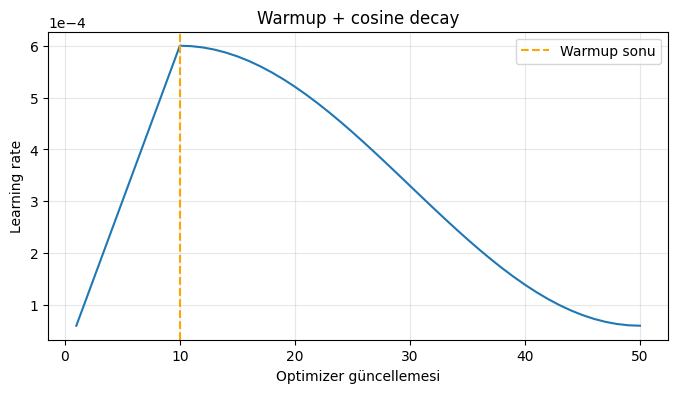

İlk güncelleme LR: 0.000060
Warmup sonu LR:    0.000600
Son güncelleme LR: 0.000060


In [ ]:
def get_lr(step):
    update = step + 1

    if update <= warmup_steps:
        return max_lr * update / warmup_steps

    if update >= max_steps:
        return min_lr

    decay_ratio = (
        (update - warmup_steps)
        / (max_steps - warmup_steps)
    )

    coefficient = 0.5 * (
        1.0 + math.cos(math.pi * decay_ratio)
    )

    return min_lr + coefficient * (max_lr - min_lr)


lr_values = [get_lr(step) for step in range(max_steps)]

plt.figure(figsize=(8, 4))
plt.plot(range(1, max_steps + 1), lr_values)
plt.axvline(
    warmup_steps,
    color="orange",
    linestyle="--",
    label="Warmup sonu",
)
plt.xlabel("Optimizer güncellemesi")
plt.ylabel("Learning rate")
plt.title("Warmup + cosine decay")
plt.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"İlk güncelleme LR: {get_lr(0):.6f}")
print(f"Warmup sonu LR:    {get_lr(warmup_steps - 1):.6f}")
print(f"Son güncelleme LR: {get_lr(max_steps - 1):.6f}")

In [ ]:
torch.manual_seed(1337)

toy_model = nn.Linear(16, 1, bias=False).double()

toy_x = torch.randn(16, 16, dtype=torch.float64)
toy_y = torch.randn(16, 1, dtype=torch.float64)


toy_model.zero_grad(set_to_none=True)

loss = F.mse_loss(toy_model(toy_x), toy_y)
loss.backward()

large_batch_grad = toy_model.weight.grad.clone()


def accumulated_gradient(divide_loss):
    toy_model.zero_grad(set_to_none=True)

    for i in range(grad_accum_steps):
        start = i * B
        end = start + B

        loss = F.mse_loss(
            toy_model(toy_x[start:end]),
            toy_y[start:end],
        )

        if divide_loss:
            loss = loss / grad_accum_steps

        loss.backward()

    return toy_model.weight.grad.clone()


wrong_grad = accumulated_gradient(divide_loss=False)
correct_grad = accumulated_gradient(divide_loss=True)

print(
    "Bölmeden hesaplanan gradient yaklaşık 8 kat mı?",
    torch.allclose(
        wrong_grad,
        large_batch_grad * grad_accum_steps,
    ),
)

print(
    "Bölerek hesaplanan gradient büyük batch ile eşleşiyor mu?",
    torch.allclose(correct_grad, large_batch_grad),
)

print(
    "Maksimum mutlak fark:",
    (correct_grad - large_batch_grad).abs().max().item(),
)

torch.testing.assert_close(correct_grad, large_batch_grad)

Bölmeden hesaplanan gradient yaklaşık 8 kat mı? True
Bölerek hesaplanan gradient büyük batch ile eşleşiyor mu? True
Maksimum mutlak fark: 1.1102230246251565e-16


In [ ]:
train_loader.current_position = 0
model_gpt3.train()

history = []
step = 0
skipped_attempts = 0

while step < max_steps:
    optimizer.zero_grad(set_to_none=True)

    lr = get_lr(step)

    for group in optimizer.param_groups:
        group["lr"] = lr

    loss_accum = torch.zeros((), device=device)

    for micro_step in range(grad_accum_steps):
        x, y = train_loader.next_batch()


        assert (y != -100).all().item(), "Eksik mikro batch geldi."

        x = x.to(device)
        y = y.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            loss = model_gpt3(x, y)
            loss = loss / grad_accum_steps

        loss_accum += loss.detach()
        scaler.scale(loss).backward()


    scaler.unscale_(optimizer)


    grad_norm = torch.nn.utils.clip_grad_norm_(
        raw_model.parameters(),
        max_norm=1.0,
    )

    scale_before = scaler.get_scale()

    scaler.step(optimizer)
    scaler.update()


    if scaler.get_scale() < scale_before:
        skipped_attempts += 1

        print(
            f"Güncelleme {step + 1} atlandı: FP16 taşması "
            f"| norm: {grad_norm.item():.4f}"
        )

        if skipped_attempts >= 10:
            raise RuntimeError(
                "Tekrarlayan FP16 taşması var; çıktıyı kontrol et."
            )

        continue

    loss_value = loss_accum.item()
    norm_value = grad_norm.item()

    history.append({
        "step": step + 1,
        "loss": loss_value,
        "lr": lr,
        "grad_norm": norm_value,
    })

    print(
        f"Adım {step + 1:02d}/{max_steps} "
        f"| loss: {loss_value:.4f} "
        f"| lr: {lr:.6f} "
        f"| grad norm (clip öncesi): {norm_value:.4f}"
    )

    step += 1

print("\nTamamlanan optimizer güncellemesi:", len(history))
print("Atlanan FP16 denemesi:", skipped_attempts)

Adım 01/50 | loss: 6.0405 | lr: 0.000060 | grad norm (clip öncesi): 2.0447
Adım 02/50 | loss: 6.0115 | lr: 0.000120 | grad norm (clip öncesi): 1.7845
Adım 03/50 | loss: 5.9792 | lr: 0.000180 | grad norm (clip öncesi): 1.3053
Adım 04/50 | loss: 5.9060 | lr: 0.000240 | grad norm (clip öncesi): 1.3172
Adım 05/50 | loss: 5.5351 | lr: 0.000300 | grad norm (clip öncesi): 1.1756
Adım 06/50 | loss: 5.3473 | lr: 0.000360 | grad norm (clip öncesi): 1.3324
Adım 07/50 | loss: 5.2470 | lr: 0.000420 | grad norm (clip öncesi): 1.1272
Adım 08/50 | loss: 5.1771 | lr: 0.000480 | grad norm (clip öncesi): 0.9807
Adım 09/50 | loss: 5.3235 | lr: 0.000540 | grad norm (clip öncesi): 1.0323
Adım 10/50 | loss: 5.1703 | lr: 0.000600 | grad norm (clip öncesi): 1.0178
Adım 11/50 | loss: 5.4110 | lr: 0.000599 | grad norm (clip öncesi): 0.8021
Adım 12/50 | loss: 5.6141 | lr: 0.000597 | grad norm (clip öncesi): 0.8661
Adım 13/50 | loss: 5.8913 | lr: 0.000593 | grad norm (clip öncesi): 1.5820
Adım 14/50 | loss: 5.8244